In [1]:
#Importing libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
!pip install -q kagglehub

In [3]:
#Loading Intel Image Classification dataset
import kagglehub

path = kagglehub.dataset_download("puneet6060/intel-image-classification")

print("Dataset downloaded to:", path)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dataset downloaded to: /kaggle/input/intel-image-classification


In [4]:
#Exploring the dataset
import os

print(os.listdir(path))

['seg_train', 'seg_pred', 'seg_test']


In [5]:
import os

train_path = os.path.join(path, "seg_train")
test_path = os.path.join(path, "seg_test")

print("Training classes:")
print(os.listdir(train_path))

print("\nTesting classes:")
print(os.listdir(test_path))

Training classes:
['seg_train']

Testing classes:
['seg_test']


In [6]:
train_path = os.path.join(path, "seg_train", "seg_train")
test_path = os.path.join(path, "seg_test", "seg_test")

print("Training folders:", os.listdir(train_path))
print("Testing folders:", os.listdir(test_path))

Training folders: ['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']
Testing folders: ['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']


In [7]:
#Understanding our dataset
for class_name in sorted(os.listdir(train_path)):
    class_path = os.path.join(train_path, class_name)
    print(class_name, ":", len(os.listdir(class_path)), "images")

buildings : 2191 images
forest : 2271 images
glacier : 2404 images
mountain : 2512 images
sea : 2274 images
street : 2382 images


In [8]:
print(os.listdir(train_path))

['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']


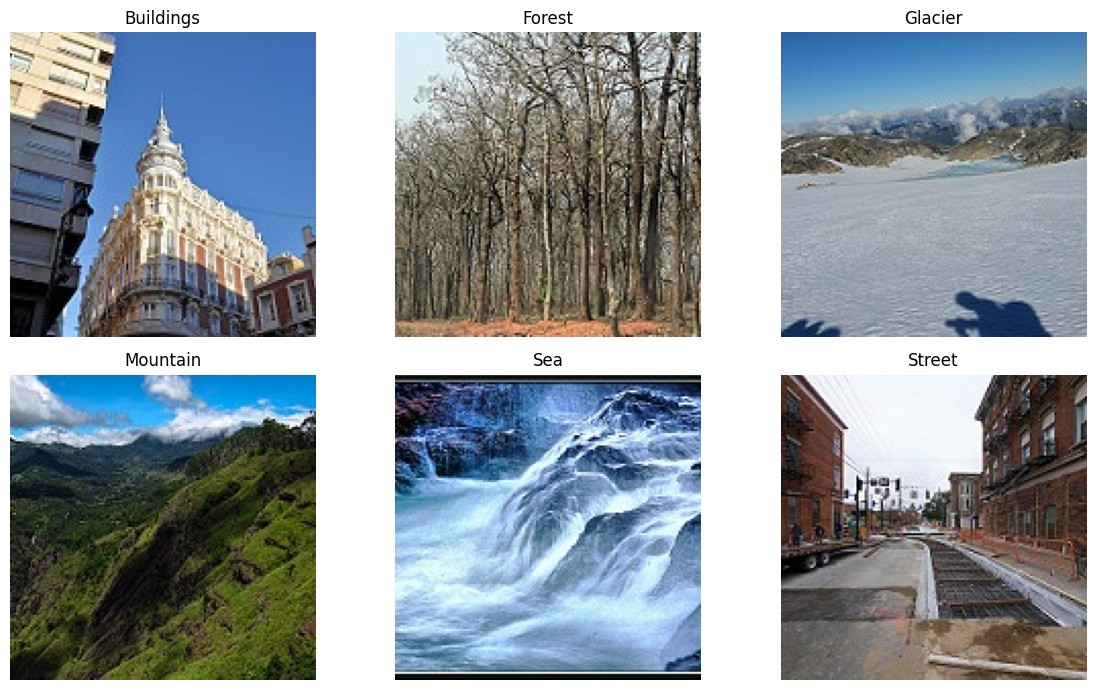

In [9]:
# Displaying sample images
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

classes = sorted(os.listdir(train_path))

plt.figure(figsize=(12, 7))

for i, class_name in enumerate(classes):
    class_folder = os.path.join(train_path, class_name)
    image_files = [
        f for f in os.listdir(class_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    image_file = random.choice(image_files)
    image_path = os.path.join(class_folder, image_file)

    img = Image.open(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name.capitalize())
    plt.axis("off")

plt.tight_layout()
plt.show()


In [10]:
#Preprocessing the images

import tensorflow as tf

IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())


Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Training batches: 351
Validation batches: 88
Test batches: 94


Resize and normalize
We'll use images of size 150 × 150 pixels.
- Resize: Makes every image the same dimensions so the CNN can process them together.
- Normalize: Converts pixel values from 0–255 to 0–1 by dividing by 255. This generally helps neural networks train more smoothly.

80% of seg_train becomes training data.

20% becomes validation data.

seg_test stays separate for our final evaluation.

shuffle=False for the test dataset preserves the image order, which will be useful when we create the confusion matrix and display predictions.

In [11]:
#Normalize and improve loading speed

normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)
val_ds = val_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)
test_ds = test_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Preprocessing complete!")


Preprocessing complete!


In [12]:
#Add data augmentation


data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

print("Data augmentation ready!")


Data augmentation ready!


Data augmentation creates slightly modified versions of training images, helping the model generalize to images it hasn't seen before.

What these layers do:
- RandomFlip: flips an image horizontally.
- RandomRotation: rotates it slightly.
- RandomZoom: zooms in or out a little.

In [13]:
# Build the CNN model

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(150, 150, 3)),
    data_augmentation,

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(6, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
#Compile the model

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")


Model compiled successfully!


In [15]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_cnn_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping, checkpoint]
)


Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.3336 - loss: 1.5281
Epoch 1: val_loss improved from None to 1.35932, saving model to best_cnn_model.keras

Epoch 1: finished saving model to best_cnn_model.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 31s 69ms/step - accuracy: 0.4019 - loss: 1.3969 - val_accuracy: 0.4373 - val_loss: 1.3593
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5049 - loss: 1.1886
Epoch 2: val_loss improved from 1.35932 to 1.14529, saving model to best_cnn_model.keras

Epoch 2: finished saving model to best_cnn_model.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.5232 - loss: 1.1578 - val_accuracy: 0.5467 - val_loss: 1.1453
Epoch 3/15
349/351 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5571 - loss: 1.0838
Epoch 3: val_loss improved from 1.14529 to 1.02309, saving model to best_cnn_model.keras

Epoch 3: finished saving model to best_cnn_model.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.5700 - loss:

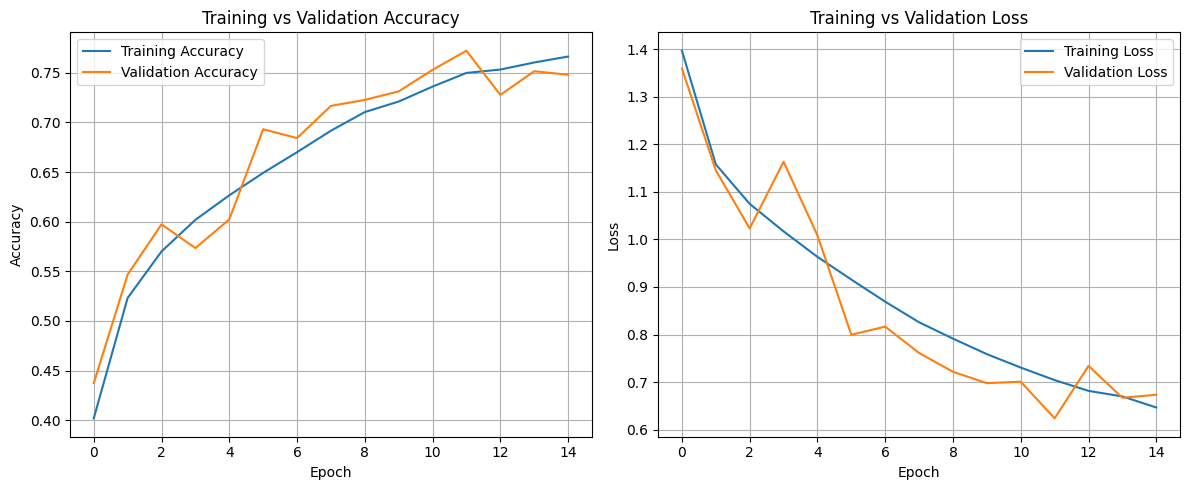

In [16]:
# Plot the training curves

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [17]:
#Evaluate the model on the test dataset

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.7603 - loss: 0.6482
Test Loss: 0.6482
Test Accuracy: 0.7603
Test Accuracy: 76.03%


94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step
              precision    recall  f1-score   support

   buildings     0.6579    0.8009    0.7224       437
      forest     0.9753    0.9156    0.9445       474
     glacier     0.8584    0.5371    0.6607       553
    mountain     0.7384    0.7257    0.7320       525
         sea     0.6662    0.8569    0.7496       510
      street     0.7564    0.7625    0.7594       501

    accuracy                         0.7603      3000
   macro avg     0.7754    0.7664    0.7614      3000
weighted avg     0.7769    0.7603    0.7586      3000



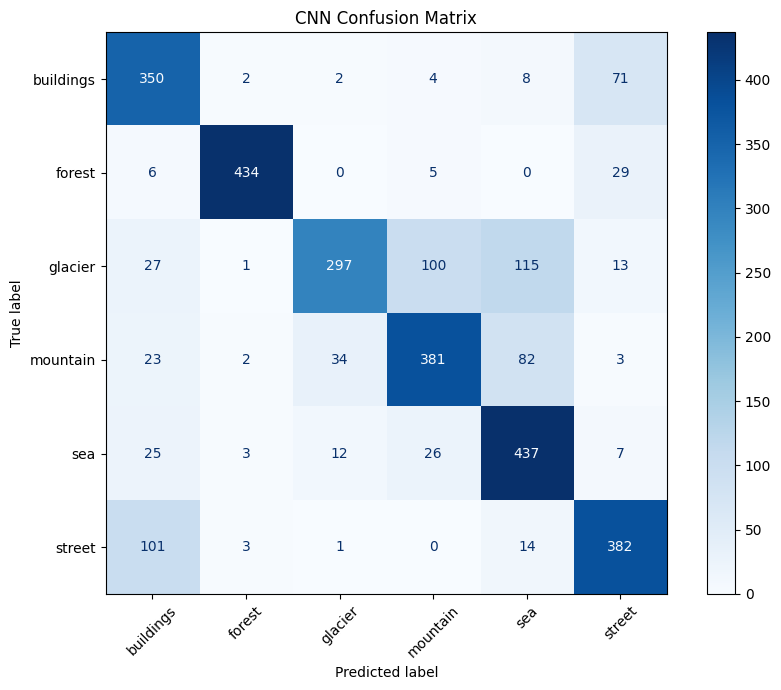

In [18]:
# Calculate precision, recall, F1-score and confusion matrix

import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()


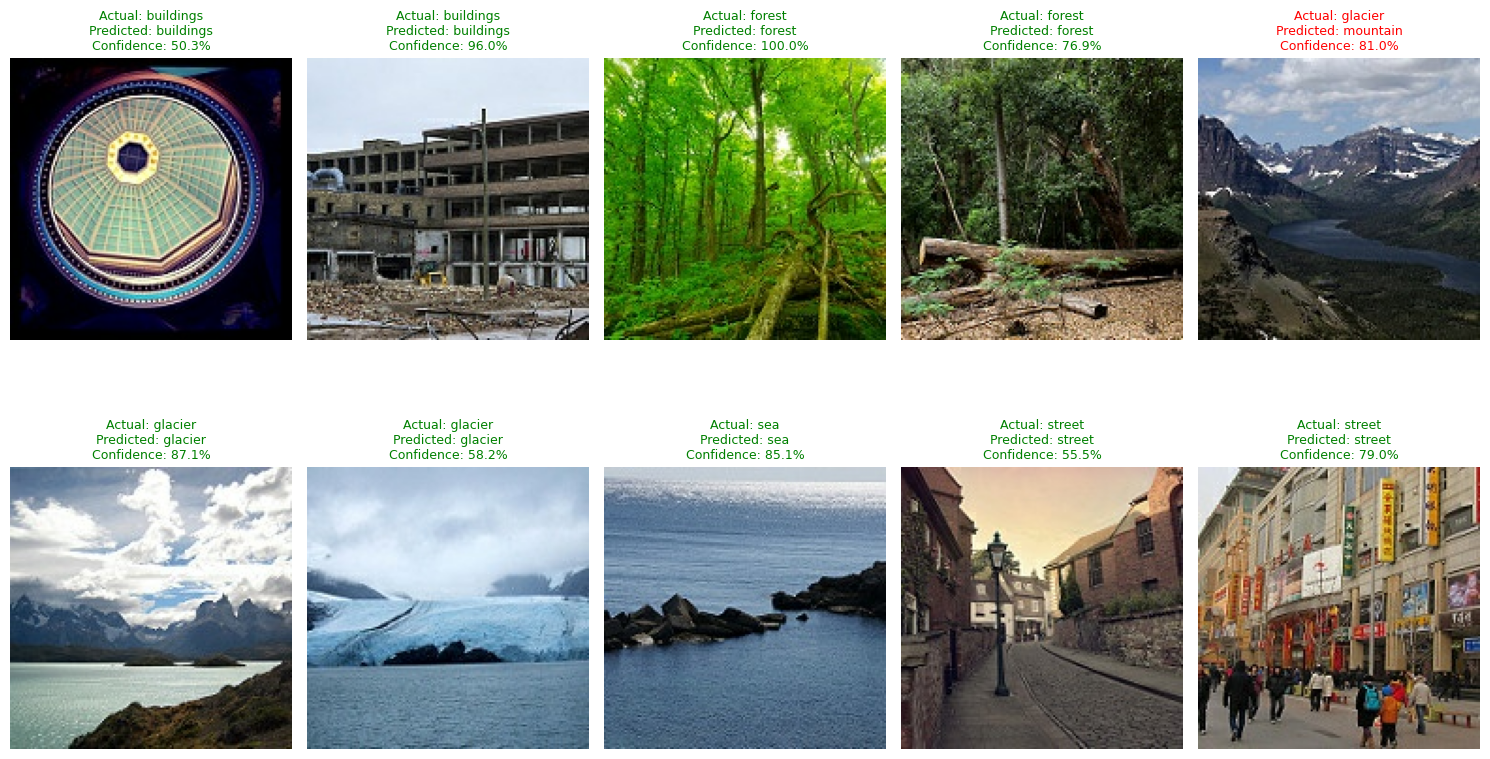

In [19]:
# Visualizing 10 predictions

import random
import numpy as np
import matplotlib.pyplot as plt

# Select 10 random test-image indices
random.seed(42)
selected_indices = set(random.sample(range(3000), 10))

selected_images = []
selected_labels = []
selected_positions = []

# Collect only the 10 selected images to save memory
for i, (image, label) in test_ds.unbatch().enumerate():
    idx = int(i.numpy())

    if idx in selected_indices:
        selected_images.append(image.numpy())
        selected_labels.append(int(label.numpy()))
        selected_positions.append(idx)

    if len(selected_images) == 10:
        break

selected_images = np.array(selected_images)
selected_labels = np.array(selected_labels)

# Predict the selected images
pred_probs = model.predict(selected_images, verbose=0)
pred_labels = np.argmax(pred_probs, axis=1)

# Display actual vs predicted labels
plt.figure(figsize=(15, 9))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(selected_images[i])

    actual = class_names[selected_labels[i]]
    predicted = class_names[pred_labels[i]]
    confidence = pred_probs[i][pred_labels[i]] * 100

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}\n"
        f"Confidence: {confidence:.1f}%",
        color=color,
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


## Conclusion

In this assignment, a Convolutional Neural Network (CNN) was developed using TensorFlow and Keras to classify natural scene images from the Intel Image Classification dataset into six categories: buildings, forest, glacier, mountain, sea, and street.

The images were resized to 150 × 150 pixels and normalized to the range [0, 1]. Data augmentation techniques, including horizontal flipping, rotation, and zooming, were used to improve generalization. The CNN architecture included three convolutional layers with ReLU activation, max-pooling layers, a global average pooling layer, a dense layer, dropout regularization, and a softmax output layer.

The model was trained using the Adam optimizer and sparse categorical cross-entropy loss. Early stopping and model checkpointing were used to retain the best-performing model weights.

On the test dataset of 3,000 images, the model achieved **76.03% accuracy**, a macro F1-score of **76.14%**, and a weighted F1-score of **75.86%**. The forest class achieved the highest F1-score at 94.45%, while glacier had the lowest recall at 53.71%.

These results demonstrate that the CNN learned useful visual patterns for natural scene classification. However, its performance varied across categories, suggesting that further improvements to the model architecture, training strategy, and data augmentation could improve classification performance.
